# D04这份数据是谁

In [1]:
%reload_ext autoreload
%autoreload 2 
# 上面这俩用于自动重载

import sqlite3 # 先导入内置的模块

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signal_insight import config, quality, viz, geo
from signal_insight.viz import (MAIN,MAIN_LIGHT,MAIN_DARK,MAIN_MID,GRAY,
                    GRAY_DARK,RED,AMBER,INK,MUTED,FAINT) # 配色常量

con = sqlite3.connect(config.DB_PATH) # 连接数据库
DAY = config.ANALYSIS_DAY
NB = "D03_信令数据洞察"
SOURCE = f"{config.SOURCE_NOTE}:脚本:{NB} 制图:{config.AUTHOR}"

## 封装测试

### 点落面封装测试

In [2]:
cell = pd.read_sql("SELECT * FROM ods_cell", con)
sites = cell[['lng', 'lat']].drop_duplicates().reset_index(drop=True)
# 给站点做编号：编号补0到S00005
sites['site_id'] = "S" + (sites.index + 1).astype(str).str.zfill(5)

districts = geo.rings_from_points(
    pd.read_sql("SELECT * FROM ods_district_boundary", con), "district")
sites['districts'] = geo.point_in_polygons(sites['lng'], sites['lat'], districts)
sites['districts'] = sites['districts'].fillna("市外")


# 没坐标点扇区定位不了
cell = cell.dropna(subset=['lng','lat']).copy()
# 不重复的坐标=一个站点
# 把站点号贴回每个扇区
cell = cell.merge(sites, on=['lng', 'lat'],how='left')

### 区域地图封装测试

In [3]:
# 读取dwd表
dwd = pd.read_sql("SELECT * FROM dwd_signal", con, parse_dates=['ts'])
# 两个表格合并
joined = dwd.merge(cell[['lac_cell', "site_id", 'lng', 'lat']],
                on='lac_cell',
                how='left')
out_share = (sites['districts'] == '市外').mean()
rec_district = joined.merge(sites[['site_id', 'districts']],
            on="site_id",how="left")
rec_out = (rec_district['districts'] =='市外').mean()

v2_pts = pd.read_sql("SELECT * FROM ods_aoi_v2", con)
aoi_v2 = geo.rings_from_points(v2_pts,"name")

sites['aoi'] = geo.point_in_polygons(sites['lng'],sites['lat'], aoi_v2)
dim_cell = cell.merge(sites[['site_id', 'aoi']],
                      on='site_id',
                      how='left')
def split_at_jump(values: pd.Series) -> tuple[list[str], list[str], float]:
    """按数值从小到大排，找相邻两项比值最大的地方切开。
    返回 (断崖之前的名字, 断崖之后的名字, 断崖处的倍数)。D3_02、D3_03 用它决定强调哪一组。"""
    v = values.sort_values()
    r = v.values[1:] / v.values[:-1]
    k = int(r.argmax())
    return list(v.index[: k + 1]), list(v.index[k + 1:]), float(r[k])

site = dim_cell.groupby('site_id').agg(
    lng=("lng", 'first'),
    lat=('lat', 'first'),
    district=('districts', 'first')
)

In [4]:
from scipy.spatial import cKDTree # pip install scipy
# ============================================================
# 2. 经纬度 → 平面公里（沈阳局部平面近似）
# ============================================================
lng0, lat0 = 123.4, 41.8
kx = 111.320 * np.cos(np.radians(lat0))   # 每度经度 ≈ 多少公里
ky = 110.574                               # 每度纬度 ≈ 多少公里
xy = np.column_stack([
    (site["lng"] - lng0) * kx,
    (site["lat"] - lat0) * ky,
]).astype(np.float64)   # cKDTree 用 float64 更稳
# ============================================================
# 3. KD 树求最近邻（等价于原来的分块暴力 + 排除自己）
# ============================================================
tree = cKDTree(xy)
# k=2：第 0 列是自己（距离 0），第 1 列是真正的最近邻
dist_km, idx = tree.query(xy, k=2)
# 取第 1 列作为最近邻距离（公里），转成米
nn = dist_km[:, 1].astype(np.float32)
site["nn_m"] = nn * 1000
# ============================================================
# 4. 各区县面积（鞋带公式，与原代码一致）
# ============================================================
area = {}
for name, rings in districts.items():
    area[name] = sum(
        0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
        for x, y in (((r[:, 0] - lng0) * kx, (r[:, 1] - lat0) * ky) for r in rings)
    )
# ============================================================
# 5. 分组统计
# ============================================================
by = (site[site["district"] != "市外"]
        .groupby("district")
        .agg(站点数=("nn_m", "size"), 间距中位_米=("nn_m", "median"))
        .sort_values("间距中位_米"))
by["每平方公里站点数"] = by["站点数"] / pd.Series(area)
by = by.round(1).reset_index()

## 用户都去过那些区

In [5]:
%reload_ext autoreload
%autoreload 2 
# 上面这俩用于自动重载

import sqlite3 # 先导入内置的模块

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signal_insight import config, quality, viz, geo
from signal_insight.viz import (MAIN,MAIN_LIGHT,MAIN_DARK,MAIN_MID,GRAY,
                    GRAY_DARK,RED,AMBER,INK,MUTED,FAINT) # 配色常量
fonts = viz.apply_theme("default")         
con = sqlite3.connect(config.DB_PATH) # 连接数据库
DAY = config.ANALYSIS_DAY
NB = "D03_信令数据洞察"
SOURCE = f"{config.SOURCE_NOTE}:脚本:{NB} 制图:{config.AUTHOR}"

districts = geo.rings_from_points(
    pd.read_sql("SELECT * FROM ods_district_boundary", con),"district"
)

aoi = geo.rings_from_points(
   pd.read_sql("SELECT * FROM ods_aoi_v2", con),"name" 
)
print(f"一共有{len(districts)}个区县,{len(aoi)}个商圈")

一共有13个区县,5个商圈


In [6]:
dwd =pd.read_sql("SELECT imsi, ts, lac_cell FROM dwd_signal", con)
dim = pd.read_sql("SELECT * FROM dim_cell", con)

sig = dwd.merge(dim, on=['lac_cell'], how='inner')
n_users = sig['imsi'].nunique()
print(f"带位置的信令有：{len(sig)}条,用户有：{n_users}个")
# 需求：10月3日这一天，有多少比例的用户到过每个区
reach = (sig.groupby('district')['imsi'].nunique() / n_users).rename('到访用户占比')
reach = reach.drop("市外", errors='ignore').sort_values().reset_index()
reach.to_sql('ads_district_rech',con,if_exists='replace', index=False)

带位置的信令有：515923条,用户有：5644个


13

In [7]:
reach['到访用户占比'] = reach['到访用户占比']  * 100

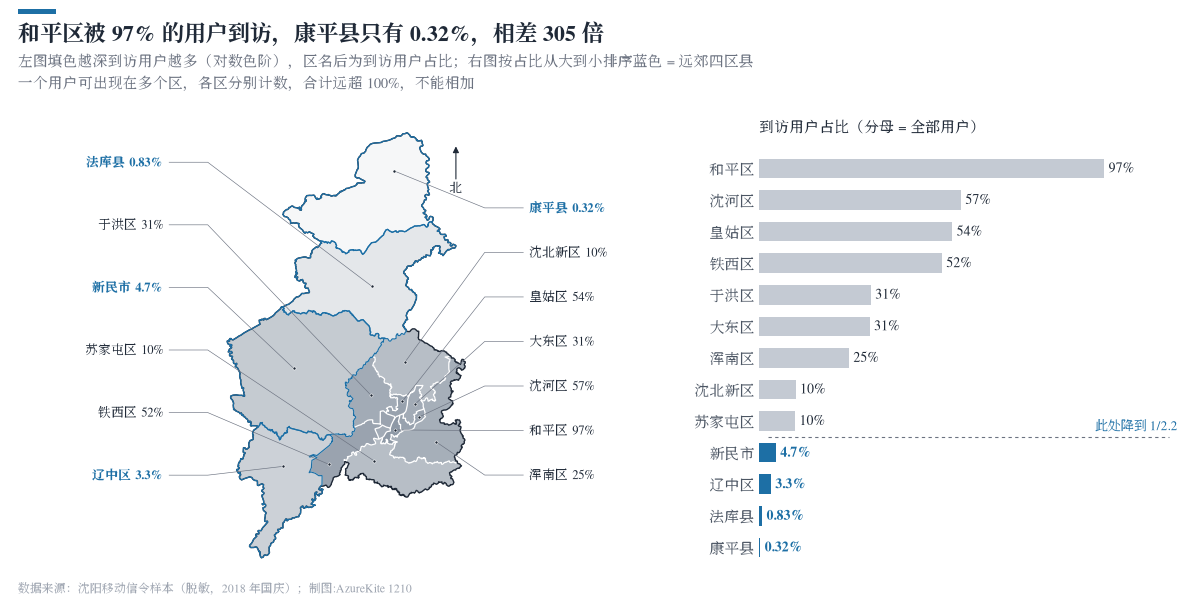

In [8]:
s = reach.sort_values(by='到访用户占比',ascending=False)   # 大 → 小，条形从上往下就是这个顺序
s.set_index('district',inplace=True)
FAR = ["新民市", "辽中区", "法库县", "康平县"]      # 远郊四区县 = 排序后垫底的四个

top, bottom = s.index[0], s.index[-1]
ratio = s.iloc[0] / s.iloc[-1]                      # 最高 ÷ 最低
cut = s.index.get_loc(FAR[0])                       # 远郊段从第几行开始
jump = s.iloc[cut - 1] / s.iloc[cut]                # 断档处掉了几倍

def pct(v: float) -> str:
    """百分比写法（规范第 6 节）：一般取整，小于 10 留一位，小于 1 留两位——很小的值不写成 0%。"""
    return f"{v:.0f}%" if v >= 10 else f"{v:.1f}%" if v >= 1 else f"{v:.2f}%"

# ── 2 版面：左地图 + 右条形 ────────────────────────────────────────────────
regions = viz.maps.Regions(districts)
H, BAR_W = 10, 5.6                                 # 地图高、条形列宽（英寸）
MAP_W = H * regions.aspect + 3.4                    # 地图本身 + 两侧引线标注
fig, (ax_map, ax_bar) = plt.subplots(
    1, 2, figsize=(12, 6),
    width_ratios=[MAP_W, BAR_W], layout="constrained")

# ── 3 左图：填色 + 引线标注 ───────────────────────────────────────────────
# 占比跨两个数量级（0.3% → 97%），填色用对数色阶；没数据的区露出底色
regions.base(ax_map, scale=False, north=dict(x=0.93, y=0.95))
regions.fill(ax_map, dict(s.reset_index().values.tolist()), norm="log")
regions.edges(ax_map, FAR, color=MAIN, lw=0.9)      # 远郊四区县整圈描蓝，和右图对上
regions.label(ax_map, dict(s.reset_index().values.tolist()), fmt=pct, hot=FAR,  split='balance')

# ── 4 右图：横向条形，远郊四区县用主色 ────────────────────────────────────
y = np.arange(len(s))
ax_bar.barh(y, s.iloc[:,0].values, height=0.62,
            color=[MAIN if n in FAR else GRAY for n in s.index])
for i, (name, v) in enumerate(zip(s.index, s.iloc[:,0].values)):
    ax_bar.text(v + 1.2, i, pct(v), va="center", fontsize=10,
                color=MAIN if name in FAR else INK,
                fontweight="bold" if name in FAR else "normal")

ax_bar.set_yticks(y, s.index, fontsize=10.5)
ax_bar.set_ylim(len(s) - 0.4, -1.4)                 # 顶上留一行放列头
ax_bar.set_xlim(0, 118)                             # 条形从 0 开始，右边留出数值的位置
ax_bar.set_xticks([])
ax_bar.grid(False)
ax_bar.tick_params(length=0)
for sp in ax_bar.spines.values():
    sp.set_visible(False)
ax_bar.text(0, -1.3, "到访用户占比（分母 = 全部用户）", 
        fontsize=10.5, color=INK, va="center")

# 断档线：掉到 1/jump 的那一行上面
ax_bar.axhline(cut - 0.5, color=MUTED, lw=0.8, 
            ls=(0, (3, 3)), xmin=0.02, xmax=0.98)
ax_bar.text(118, cut - 0.62, f"此处降到 1/{jump.values[0]:.1f}", ha="right", va="bottom",
            fontsize=9.5, color=MAIN)

# ── 5 标题区、来源行、保存 ────────────────────────────────────────────────
viz.finish(
    fig,
    f"{top}被 {pct(s.iloc[0,0])} 的用户到访，{bottom}只有 {pct(s.iloc[-1,0])}，相差 {ratio.values[0]:.0f} 倍",
    "左图填色越深到访用户越多（对数色阶），区名后为到访用户占比；右图按占比从大到小排序"
    f"蓝色 = 远郊四区县\n"
    "一个用户可出现在多个区，各区分别计数，合计远超 100%，不能相加",
    f"数据来源：沈阳移动信令样本（脱敏，2018 年国庆）；制图:{config.AUTHOR}",
    "D3_04_区县到访占比.png",
)
plt.show()

::: SUMMARY 结论
10月3日，97%的样本都到过和平区，其他区县的到访比例在57%以下。分布明显集中于和平区，说明样本样本并非全市随机抽样，结论不能推广到全市。所以需要限定数据分析范围。
:::

::: TIP 提示：大模型作图注意事项
- 数据不要无脑发：发前几行，大致描述下数据，什么类型，series和datafarme数据差的很远
- 不要发全量数据
- 发的时候：把你的本地包可以打成压缩包发给他，或者给它发包的文档.
:::

## 热点在哪里?

需求：用户都集中去了和平区的哪里？找出连接最多的基站，看看附近是什么地方

In [9]:
site_users = sig.groupby(
    ['site_id', 'lng', 'lat'])['imsi'].nunique() \
    .rename("用户数").reset_index()  \
    .sort_values("用户数",ascending=False,ignore_index=True)
site_users['用户占比'] = site_users['用户数'] / n_users
site_users.head(5)

top5 = site_users.head(5)
hot_lng = np.average(top5['lng'], weights=top5['用户数'])
hot_lat = np.average(top5['lat'], weights=top5['用户数'])
poi = pd.read_sql("SELECT * FROM ods_poi_purpose",con)
poi['距热点(米)'] = geo.haversine(poi['lat'],poi['lng'],hot_lat,hot_lng).round()
poi.nsmallest(6,"距热点(米)")[['name','type','距热点(米)']]

dim_hotspot = pd.DataFrame([{
    "name": "西塔", "lng": hot_lng, "lat":hot_lat, "radius_m": 500,
    "依据": "连接用户数前5名的站点按用户数加权的重心，附近为韩百商场等一带"
}])
dim_hotspot.to_sql("dim_hotspot", con, if_exists="replace", index=False)
dim_hotspot

,name,lng,lat,radius_m,依据
0,西塔,123.410582,41.806944,500,连接用户数前5名的站点按用户数加权的重心，附近为韩百商场等一带


```text
site_users构建过程：
site_users = sig.groupby(
    ['site_id', 'lng', 'lat'])['imsi'].nunique() \
    .rename("用户数").reset_index()  \
    .sort_values("用户数",ascending=False,ignore_index=True)
site_users['用户占比'] = site_users['用户数'] / n_users
输出前5行数据如下
print(site_users.head().to_markdown()) # site_users是个dataframe
|    | site_id   |     lng |     lat |   用户数 |   用户占比 |
|---:|:----------|--------:|--------:|---------:|-----------:|
|  0 | S07814    | 123.409 | 41.8089 |     2300 |   0.407512 |
|  1 | S07823    | 123.412 | 41.8079 |     1769 |   0.31343  |
|  2 | S07364    | 123.413 | 41.8047 |     1648 |   0.291991 |
|  3 | S07363    | 123.411 | 41.8059 |     1633 |   0.289334 |
|  4 | S13669    | 123.409 | 41.8064 |     1146 |   0.203047 |

继续处理拿到如下信息：
top5 = site_users.head(5)
hot_lng = np.average(top5['lng'], weights=top5['用户数'])
hot_lat = np.average(top5['lat'], weights=top5['用户数'])
poi = pd.read_sql("SELECT * FROM ods_poi_purpose",con)
poi['距热点(米)'] = geo.haversine(poi['lat'],poi['lng'],hot_lat,hot_lng).round()
poi.nsmallest(6,"距热点(米)")[['name','type','距热点(米)']]

print(poi.nsmallest(6,"距热点(米)")[
    ['name','type','距热点(米)']].to_markdown())

|      | name               | type   |   距热点(米) |
|-----:|:-------------------|:-------|-------------:|
|  973 | 韩百商场           | 购物   |           17 |
| 1116 | 韩百商场A座        | 购物   |           47 |
| 1049 | 博曼广场           | 购物   |          168 |
|  687 | 安图社区           | 居住   |          230 |
| 1050 | 鑫韩城购物广场     | 购物   |          257 |
| 1007 | 沈阳朝鲜族百货大楼 | 购物   |          273 |

左边地图，局部 放大放到右边，然后显示该区域的基站分布，其中连接的比较大的用大的点，类似气泡图再平面地图上，

dim_hotspot = pd.DataFrame([{
    "name": "西塔", "lng": hot_lng, "lat":hot_lat, "radius_m": 500,
    "依据": "连接用户数前5名的站点按用户数加权的重心，附近为韩百商场等一带"
}])

绘制一个圈标记西塔这个地区周边500米，实际上几个热点区域就是再西塔一带附近
```

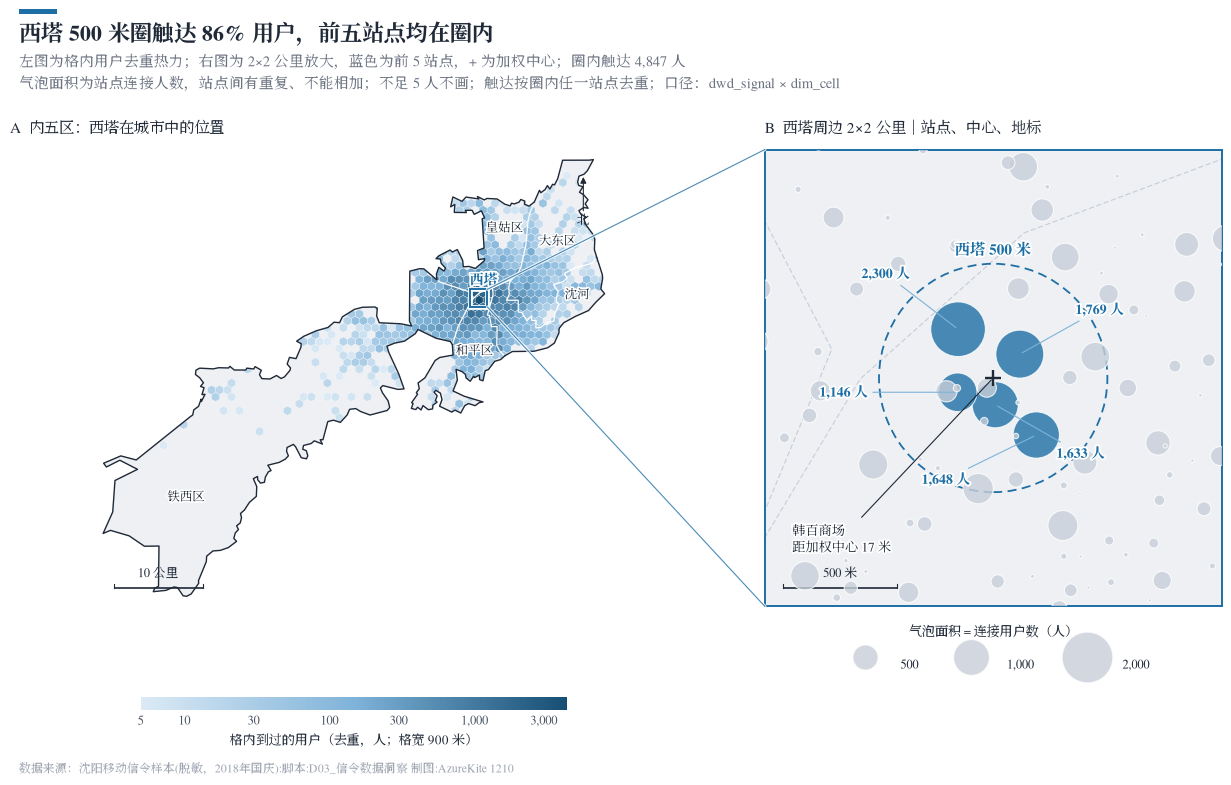

In [10]:
# ── D4_02：内五区热力 + 西塔放大；hb 保留给下一格检查 ──
core_names = ['铁西区', '和平区', '沈河区', '皇姑区', '大东区']
core = viz.maps.Regions({n: districts[n] for n in core_names})
hs = dim_hotspot.loc[dim_hotspot['name'].eq('西塔')].iloc[0]
lng, lat, radius_m = (float(hs['lng']), float(hs['lat']), float(hs['radius_m']))
sites = site_users.sort_values('用户数', ascending=False).copy()
top = sites.head(5)
distances = geo.haversine(sig['lat'], sig['lng'], lat, lng)
reach_n = sig.loc[distances <= radius_m, 'imsi'].nunique()
reach_pct = reach_n / sig['imsi'].nunique()
top_in = int((geo.haversine(top['lat'], top['lng'], lat, lng) <= radius_m).sum())
fig, (amap, az) = plt.subplots(1, 2, figsize=(13, 7.8),
                               width_ratios=[core.aspect * 1.06, 1], layout='constrained')
core.base(amap, north=dict(x=0.94, y=0.94))
hb = core.hexbin(amap, sig, 900, value='imsi', how='nunique', min_value=5)
core.text(amap, dict.fromkeys(core_names, np.nan), alias={'沈河区': '沈河'}, overflow='hide')
viz.maps.colorbar(hb, amap, label='格内到过的用户（去重，人；格宽 900 米）')
amap.set_title('A  内五区：西塔在城市中的位置', loc='left', fontsize=11, pad=12)
core.base(az, fill=False, outline=False, north=False,
          borders=dict(color='#C4CDD8', lw=0.8, ls=(0, (4, 3))))
viz.maps.zoom(amap, az, lng, lat, 1000, label='西塔', connect=True)
core.bubbles(az, sites, '用户数', hot=sites['site_id'].isin(top['site_id']), min_value=5, color='#C8CFD9',
             hot_color=MAIN, smax=1550, alpha=0.8, vmax=sites['用户数'].max(), ref=[500, 1000, 2000], title='气泡面积 = 连接用户数（人）')
viz.maps.circle(az, lng, lat, radius_m)
az.scatter([lng], [lat], marker='+', s=120, color=INK, lw=1.7, zorder=7)
ry = viz.maps.m2deg(radius_m, lat)[1]
az.text(lng, lat + ry * 1.08, f'西塔 {radius_m:,.0f} 米', ha='center', fontsize=11,
        color=MAIN, fontweight='bold', path_effects=viz.maps.HALO, zorder=7)
offsets = [(-35, 40), (40, 32), (-48, -32), (44, -35), (-65, 0)]
for (_, row), (dx, dy) in zip(top.iterrows(), offsets):
    if row['用户数'] < 5:
        continue
    az.annotate(f"{row['用户数']:,.0f} 人", (row['lng'], row['lat']), xytext=(dx, dy), textcoords='offset points', ha='right' if dx < 0 else 'left', va='center',
                fontsize=10, color=MAIN, fontweight='bold', path_effects=viz.maps.HALO, zorder=8, arrowprops=dict(arrowstyle='-', color=MAIN_MID, lw=0.8))
if poi is not None and len(poi):
    p = poi.copy()
    p['_distance'] = geo.haversine(p['lat'], p['lng'], lat, lng)
    nearest = p.loc[p['_distance'].idxmin()]
    az.annotate(f"{nearest['name']}\n距加权中心 {nearest['_distance']:.0f} 米", (lng, lat), xytext=(0.06, 0.12), textcoords='axes fraction',
                fontsize=9.5, color=INK, path_effects=viz.maps.HALO, zorder=9, arrowprops=dict(arrowstyle='-', color=INK, lw=0.8))
az.set_title('B  西塔周边 2×2 公里｜站点、中心、地标', loc='left', fontsize=11, pad=12)
top_note = '前五站点均在圈内' if top_in == 5 else f'前五站点有 {top_in} 个在圈内'
title = f'西塔 {radius_m:,.0f} 米圈触达 {reach_pct:.0%} 用户，{top_note}'
viz.finish(
    fig, title, f'左图为格内用户去重热力；右图为 2×2 公里放大，蓝色为前 5 站点，+ 为加权中心；圈内触达 {reach_n:,} 人\n气泡面积为站点连接人数，站点间有重复、不能相加；不足 5 人不画；触达按圈内任一站点去重；口径：dwd_signal × dim_cell', SOURCE, 'D4_02_西塔热点.png')
plt.show()


## 距离阈值变化一下，到过的人数会变成什么样子